In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report, f1_score

In [ ]:
df = pd.read_csv('/content/unijos_student_scores.csv')
df.head()

,Matric_No,Full_Name,Department,CA_Score_30,Exam_Score_70,Total_Score_100,Grade,GP
0,UJ/2025/NS/0001,Eze Abubakar,Microbiology,22.8,48.6,71.4,A,5.0
1,UJ/2025/NS/0002,Mustapha Musa,Biochemistry,20.4,50.8,71.2,A,5.0
2,UJ/2025/NS/0003,Oyinlola Tunde,Biochemistry,22.5,38.7,61.2,B,4.0
3,UJ/2025/NS/0004,Idris Musa,Economics,27.1,53.8,80.9,A,5.0
4,UJ/2025/NS/0005,Alabi Emeka,Economics,20.9,50.5,71.4,A,5.0


In [ ]:
# We select our feature columns (X) and target column (y)
X = df[['CA_Score_30', 'Exam_Score_70', 'Total_Score_100']]
y = df['Grade']

print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

Features (X) shape: (100, 3)
Target (y) shape: (100,)


In [ ]:
# Split the dataset into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Initialize and fit the scaler on the training data, then transform both train and test sets
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training set shape:", X_train_scaled.shape)
print("Testing set shape:", X_test_scaled.shape)

Training set shape: (80, 3)
Testing set shape: (20, 3)


In [ ]:
# find best K
print("finding best K")
best_k = 0
best_accuracy = 0
for k in range(1, 11):
    knn = KNeighborsClassifier(n_neighbors=k, metric="euclidean")
    knn.fit(X_train_scaled, y_train)
    acc = accuracy_score(y_test, knn.predict(X_test_scaled))
    if acc > best_accuracy:
        best_accuracy = acc
        best_k = k
    print(f"K={k}, Accuracy={acc * 100:.2f}%")

print(f"\nBest K={best_k}, Accuracy={best_accuracy * 100:.2f}%")

finding best K
K=1, Accuracy=95.00%
K=2, Accuracy=85.00%
K=3, Accuracy=90.00%
K=4, Accuracy=85.00%
K=5, Accuracy=80.00%
K=6, Accuracy=85.00%
K=7, Accuracy=80.00%
K=8, Accuracy=85.00%
K=9, Accuracy=80.00%
K=10, Accuracy=80.00%

Best K=1, Accuracy=95.00%


In [ ]:
# Train final model with best K=1
final_knn = KNeighborsClassifier(n_neighbors=1, metric='euclidean')
final_knn.fit(X_train_scaled, y_train)
pred=final_knn.predict(X_test_scaled)
print("Accuracy:", accuracy_score(y_test, pred)*100)

# Make predictions on test set
y_pred = final_knn.predict(X_test_scaled)

# Display detailed metrics
print("Classification Report:")
print(classification_report(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 95.0
Classification Report:
              precision    recall  f1-score   support

           A       1.00      0.75      0.86         4
           B       0.91      1.00      0.95        10
           C       1.00      1.00      1.00         5
           D       1.00      1.00      1.00         1

    accuracy                           0.95        20
   macro avg       0.98      0.94      0.95        20
weighted avg       0.95      0.95      0.95        20

Confusion Matrix:
[[ 3  1  0  0]
 [ 0 10  0  0]
 [ 0  0  5  0]
 [ 0  0  0  1]]


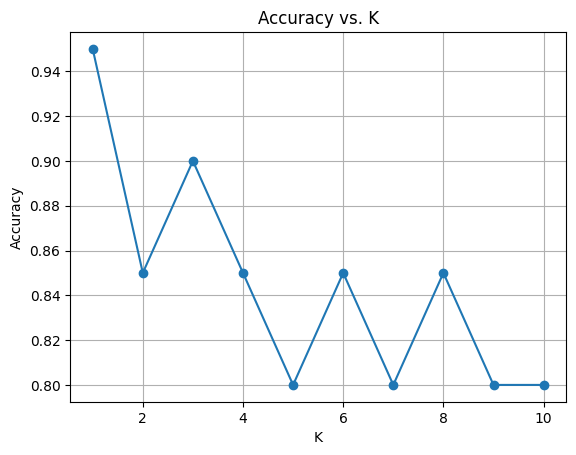

In [ ]:
plt.plot(range(1, 11), accuracy_scores, marker='o')
plt.xlabel('K')
plt.ylabel('Accuracy')
plt.title('Accuracy vs. K')
plt.grid(True)
plt.show()

In [ ]:
# Provide a sample containing 3 values: [CA_Score_30, Exam_Score_70, Total_Score_100]
new_sample = scaler.transform([[25.0, 45.0, 70.0]])
print("Predicted Grade:", final_knn.predict(new_sample)[0])

Predicted Grade: B


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
